# Part 2 of Deep Learning HW1
Author: Daniel Bond

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

In [2]:
train_x = pd.read_csv("train_x_bronze.csv.gz")
train_y = pd.read_csv("train_y_bronze.csv.gz")
test = pd.read_csv("test_bronze.csv.gz")
test_ids = test["SK_ID_CURR"].copy()
test.drop(columns=["SK_ID_CURR"], inplace=True)

with open("meta.json") as f:
    meta = json.load(f)

cat_cols = meta["cat_cols"]
cardinalities = meta["cardinalities"]
emb_dims = meta["emb_dims"]

In [3]:
train_x

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,NONLIVINGAPARTMENTS_MODE_missing,NONLIVINGAREA_MODE_missing,TOTALAREA_MODE_missing,AMT_REQ_CREDIT_BUREAU_HOUR_missing,AMT_REQ_CREDIT_BUREAU_DAY_missing,AMT_REQ_CREDIT_BUREAU_WEEK_missing,AMT_REQ_CREDIT_BUREAU_MON_missing,AMT_REQ_CREDIT_BUREAU_QRT_missing,AMT_REQ_CREDIT_BUREAU_YEAR_missing,n_missing_num
0,1,2,1,2,-0.577538,0.377778,-0.478095,-0.166143,-0.507236,8,...,0,0,0,0,0,0,0,0,0,-1.408448
1,1,1,1,1,-0.577538,1.112042,1.725450,0.592683,1.600873,2,...,0,0,0,0,0,0,0,0,0,-1.268859
2,2,2,2,2,-0.577538,-1.090751,-1.152888,-1.404669,-1.092145,8,...,1,1,1,0,0,0,0,0,0,0.685386
3,1,1,1,2,-0.577538,-0.356486,-0.711430,0.177874,-0.653463,8,...,1,1,1,1,1,1,1,1,1,1.802097
4,1,2,1,2,-0.577538,-0.503339,-0.213734,-0.361749,-0.068554,8,...,1,1,1,0,0,0,0,0,0,0.964564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,1,2,1,1,-0.577538,-0.111732,-0.855489,0.031015,-0.848433,8,...,0,0,0,1,1,1,1,1,1,-0.431325
307507,1,1,1,2,-0.577538,-1.041800,-0.818594,-1.042333,-0.848433,8,...,0,0,0,1,1,1,1,1,1,-0.152147
307508,1,1,1,2,-0.577538,-0.160683,0.195379,0.198056,0.126415,8,...,0,0,0,0,0,0,0,0,0,-1.268859
307509,1,1,1,2,-0.577538,0.035121,-0.568757,-0.476318,-0.592535,8,...,1,1,0,0,0,0,0,0,0,-0.012558


## Validation
As presented in Part 1, the classes are severely unbalanced, so validation strategy needs to represent this - stratified K-Fold is the natural choice, as it will keep the pos/neg ratio between splits, compared to basic K-Fold, which would have each fold with a different ratio, possibly harming the model's performance. Also, the data contains no time-series based data, so taking random splits is not a problem.

In [4]:
# skf split, set state for reproduction
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

folds = np.full(len(train_x), -1, dtype="int8")
for fold, (_, val_idx) in enumerate(skf.split(train_x, train_y)):
    folds[val_idx] = fold
folds

array([4, 4, 3, ..., 0, 4, 1], dtype=int8)

### Correlation with Public/Private leaderboards
I expect the scores received here to approximately reflect the scores on leaderboards.

#### Why should it be correlated:

- The dataset is relatively large CV should produce low-variance scores.
- It is likely that test set has similar class distribution.

#### Why not:

- Public/Private use different parts of test set and those can have different distributions.
- Features might have different characteristics on test compared to train
- Overfitting, while being limited by CV, can still become a problem

In [5]:
# Adversarial validation
X_adv = pd.concat([train_x, test], ignore_index=True)
y_adv = np.r_[np.zeros(len(train_x)), np.ones(len(test))]
model = LGBMClassifier(n_estimators=50, verbose=-1)
oof = cross_val_predict(model, X_adv, y_adv, cv=skf, method="predict_proba")[:, 1]
print("Adversarial AUC:", roc_auc_score(y_adv, oof))

Adversarial AUC: 0.8949289953813145


The adversarial results are pretty bad - they show that tree model manages to identify from which dataset was the data (train/test).

Running the test to check it's impact on score:

In [6]:
main = LGBMClassifier(n_estimators=50, verbose=-1)
y1 = train_y.values.ravel()
p_test_like = oof[:len(train_x)]
test_like = p_test_like >= np.quantile(p_test_like, 0.8)

oof_main = cross_val_predict(main, train_x, y1, cv=skf, method="predict_proba")[:, 1]
print("CV AUC (all train):  ", roc_auc_score(y1, oof_main))
print("CV AUC (test-like):  ", roc_auc_score(y1[test_like], oof_main[test_like]))

CV AUC (all train):   0.7534410762063892
CV AUC (test-like):   0.7505944711536618


While the shift in data distribution between sets is clear, the impact on CV score is ok, so it should be trustworthy enough (though now there is a valid reason to suspect that submission score will be different from local, not in a good side)

## Machine Learning Baseline
Baseline model: LightGBM

In [7]:
import lightgbm as lgb
from sklearn.metrics import average_precision_score, log_loss
import random, time
random.seed(67)

In [12]:
def run_cv(params, X, y, X_test, folds, n_folds=None):
    n_folds = n_folds or folds.max() + 1
    oof = np.zeros(len(X)); test_pred = np.zeros(len(X_test))
    fold_auc, imps = [], []
    for k in range(n_folds):
        tr, va = folds != k, folds == k
        m = LGBMClassifier(**params, n_estimators=2000, max_bin=63, n_jobs=-1, verbose=-1)
        m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], eval_metric="auc", callbacks=[lgb.early_stopping(50, verbose=False)])
        oof[va] = m.predict_proba(X[va])[:, 1]
        test_pred += m.predict_proba(X_test)[:, 1] / n_folds
        fold_auc.append(roc_auc_score(y[va], oof[va]))
        imps.append(pd.Series(m.booster_.feature_importance("gain"), index=X.columns))
        print(f"{k} folds done")
    return oof, test_pred, fold_auc, imps

The parameters here are deliberately selected to improve training speed:

only 2 folds out of 5 are used, learning rate kept high, limited tree size etc.

In [13]:
params = {
    "learning_rate": [0.05, 0.1], "num_leaves": [15, 31, 63],
    "min_child_samples": [20, 50, 100], "colsample_bytree": [0.5, 0.7, 0.9],
    "reg_lambda": [0, 1, 5]
  }
log = []
for t in range(6):
    p = {k: random.choice(v) for k, v in params.items()}
    t0 = time.time()
    _, _, fa, _ = run_cv(p, train_x, y1, test, folds, n_folds=2)
    log.append({**p, "cv_auc": np.mean(fa), "cv_std": np.std(fa), "sec": time.time() - t0})
    print(f"trial {t}: AUC {log[-1]['cv_auc']:.5f} ± {log[-1]['cv_std']:.5f}, {log[-1]['sec']:.0f}s")
    pd.DataFrame(log).to_csv("lgbm_tuning_log.csv", index=False)

0 folds done
1 folds done
trial 0: AUC 0.75672 ± 0.00024, 59s
0 folds done
1 folds done
trial 1: AUC 0.75874 ± 0.00045, 65s
0 folds done
1 folds done
trial 2: AUC 0.75858 ± 0.00012, 97s
0 folds done
1 folds done
trial 3: AUC 0.75802 ± 0.00022, 90s
0 folds done
1 folds done
trial 4: AUC 0.75648 ± 0.00004, 41s
0 folds done
1 folds done
trial 5: AUC 0.75878 ± 0.00064, 83s


In [14]:
display(pd.DataFrame(log).sort_values("cv_auc", ascending=False))

,learning_rate,num_leaves,min_child_samples,colsample_bytree,reg_lambda,cv_auc,cv_std,sec
5,0.10,15,50,0.5,1,0.758783,0.000644,83.058820
1,0.10,31,20,0.7,5,0.758743,0.000446,64.786929
2,0.05,31,100,0.9,5,0.758584,0.000119,97.499708
3,0.05,15,50,0.9,0,0.758020,0.000220,89.829371
0,0.10,15,20,0.9,0,0.756719,0.000242,59.299304
4,0.10,63,20,0.9,5,0.756478,0.000042,40.797573


As expected, ROC-AUC stays approximately the same as during adversarial validation. It is possible that a small range of parameter trials didn't allow for better training

Best params: {'learning_rate': 0.1, 'num_leaves': 15, 'min_child_samples': 50, 'colsample_bytree': 0.5, 'reg_lambda': 1}
0 folds done
1 folds done
2 folds done
3 folds done
4 folds done
Per-fold AUC: [0.75943 0.75814 0.75336 0.75779 0.76321]
CV AUC:        0.75838 ± 0.00316
OOF AUC:       0.75837
PR-AUC:        0.24111
LogLoss:       0.24622
Recall@10%:    0.33462
AUC test-like: 0.75517


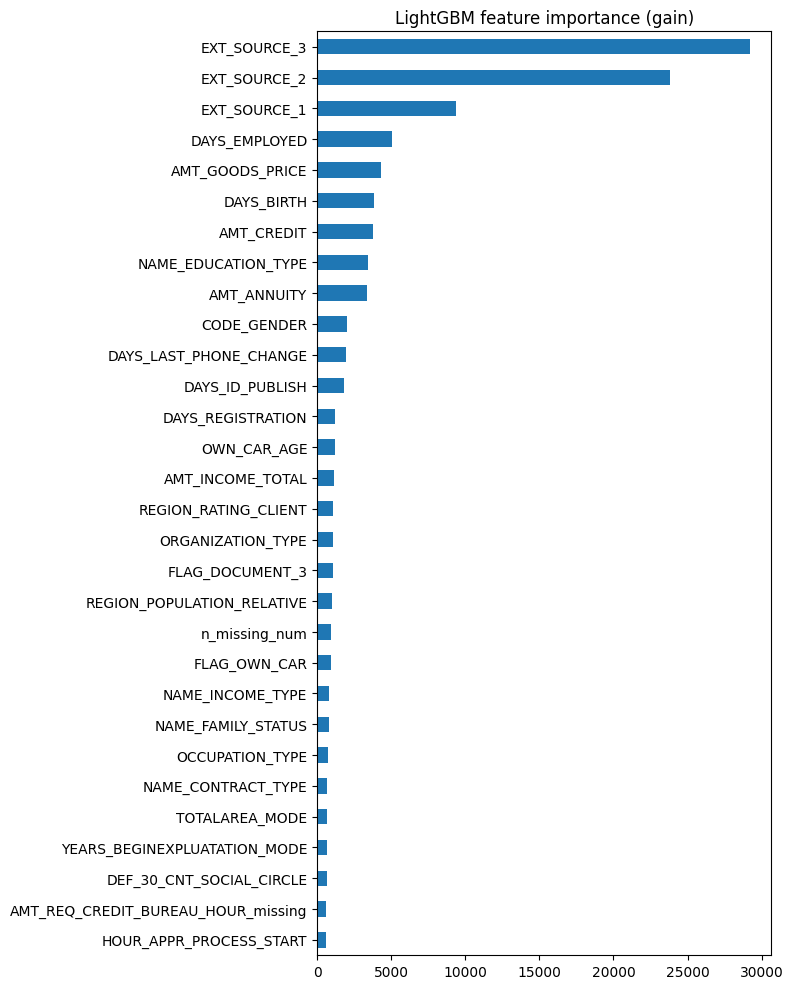

In [15]:
best = max(log, key=lambda r: r["cv_auc"])
best_params = {k: best[k] for k in params}
print("Best params:", best_params)

oof_lgbm, test_lgbm, fold_auc, imps = run_cv(best_params, train_x, y1, test, folds)

def recall_at_k(y_true, p, k=0.10): # the alternative discussed in part1
    thr = np.quantile(p, 1 - k)
    return (p[y_true == 1] >= thr).mean()

# metrics
print("Per-fold AUC:", np.round(fold_auc, 5))
print(f"CV AUC:        {np.mean(fold_auc):.5f} ± {np.std(fold_auc):.5f}")
print(f"OOF AUC:       {roc_auc_score(y1, oof_lgbm):.5f}")
print(f"PR-AUC:        {average_precision_score(y1, oof_lgbm):.5f}")
print(f"LogLoss:       {log_loss(y1, oof_lgbm):.5f}")
print(f"Recall@10%:    {recall_at_k(y1, oof_lgbm):.5f}")
print(f"AUC test-like: {roc_auc_score(y1[test_like], oof_lgbm[test_like]):.5f}")

imp = pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)
imp.head(30).plot.barh(figsize=(8, 10), title="LightGBM feature importance (gain)").invert_yaxis()
plt.tight_layout()
plt.show()

np.save("oof_lgbm.npy", oof_lgbm)
np.save("test_lgbm.npy", test_lgbm)
pd.DataFrame({"SK_ID_CURR": test_ids.values, "TARGET": test_lgbm}).to_csv("sub_lgbm.csv", index=False)

### Results
Local: 0.758

Public leaderboard: 0.74715

Private leaderboard: 0.74489

Conclusion: The tuned LightGBM shows decent result on ROC-AUC, but recall score is more informative for evaluation - rejecting the riskiest 10% caught 33.5% of defaults with class rate of ~8%. The expected correlation established in "Validation" section successfully confirmed, along with the suspicion that leaderboard scores will be noticably worse ( ~3-4x std) due to distribution shifts in test data. Feature importance shows that EXT_SOURCE_[1,2,3] have dominated amongst other features, giving more gain than all other features combined.

Overall, the model is adequate as a baseline: stable validation across folds, sits far below the top of the leaderboard, which is expected given the small tuning budget and lack of feature engineering.